<a href="https://colab.research.google.com/github/srigstinahf/Proyek_SpecialSkill02_USL/blob/main/ProjectCamp02_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project Camp 02 — Clustering Saham LQ45 Berdasarkan Karakter Pergerakan Harga



## Deskripsi Proyek
Notebook ini mengelompokkan saham-saham **LQ45** secara otomatis menggunakan **algoritma K-Means** berdasarkan sifat pergerakan harganya, tanpa memberikan label/petunjuk apapun ke komputer terlebih dahulu.

Inilah yang disebut **"Unsupervised Learning"**, komputer belajar sendiri menemukan pola tersembunyi dari data.

- **Algoritma:** K-Means Clustering
- **Dataset:** 30 Saham LQ45 dari Bursa Efek Indonesia (BEI)

---

## Alur Notebook
1. Install & Import Library
2. Daftar Saham LQ45 yang Akan Dianalisis
3. Download Data Harga Saham
4. Menghitung Fitur (Karakteristik) Setiap Saham
5. Normalisasi Data (Standardisasi)
6. Menentukan Jumlah Cluster Optimal (Metode Elbow)
7. Menjalankan Algoritma K-Means Clustering
8. Interpretasi & Penamaan Cluster
9. Visualisasi Hasil Clustering (Scatter Plot)
10. Ringkasan Hasil & Kesimpulan


---
## Bagian 1: Install & Import Library
Library adalah kumpulan kode siap pakai yang memudahkan pekerjaan. Di sini saya mengimpor tools untuk mengunduh data saham, manipulasi data, visualisasi, dan algoritma machine learning.


In [ ]:
# Install library yfinance jika belum ada (khusus Google Colab)
# yfinance = Yahoo Finance, digunakan untuk mengambil data harga saham gratis
# !pip install yfinance --quiet   ← hapus tanda # jika perlu install
import yfinance as yf          # Library untuk download data saham dari Yahoo Finance
import pandas as pd            # Library untuk manipulasi data dalam bentuk tabel (DataFrame)
import numpy as np             # Library untuk operasi matematika/numerik
import matplotlib.pyplot as plt  # Library untuk membuat grafik dan visualisasi
import warnings                # Library untuk mengelola pesan peringatan
warnings.filterwarnings('ignore')  # Sembunyikan peringatan agar output lebih bersih

# Import fungsi-fungsi machine learning dari scikit-learn
from sklearn.preprocessing import StandardScaler  # Untuk normalisasi data agar skala seragam
from sklearn.cluster import KMeans               # Algoritma K-Means Clustering
from sklearn.decomposition import PCA            # PCA = Principal Component Analysis, untuk reduksi dimensi
                                                 # (memudahkan visualisasi ke 2D)

print("✅ Semua library berhasil diimport!")

✅ Semua library berhasil diimport!


---
## Bagian 2: Daftar Saham LQ45 yang Akan Dianalisis
**LQ45** adalah indeks yang berisi 45 saham paling likuid di Bursa Efek Indonesia (BEI). Saya memilih 30 saham populer dari indeks ini sebagai objek analisis clustering.


In [ ]:
# LQ45 adalah indeks 45 saham paling likuid di Bursa Efek Indonesia (BEI)
# Kita ambil 30 saham populer dari LQ45 untuk analisis ini
# Format ticker Yahoo Finance untuk saham Indonesia: KODE.JK
# Contoh: BBCA.JK = saham Bank BCA di Jakarta Stock Exchange (JK)
saham_lq45 = [
    'BBCA.JK',  # Bank Central Asia - bank swasta terbesar
    'BBRI.JK',  # Bank Rakyat Indonesia - bank BUMN terbesar
    'TLKM.JK',  # Telkom Indonesia - perusahaan telekomunikasi BUMN
    'ASII.JK',  # Astra International - konglomerat otomotif
    'BMRI.JK',  # Bank Mandiri - bank BUMN
    'UNVR.JK',  # Unilever Indonesia - perusahaan consumer goods
    'GGRM.JK',  # Gudang Garam - perusahaan rokok
    'HMSP.JK',  # HM Sampoerna - perusahaan rokok
    'ICBP.JK',  # Indofood CBP - makanan & minuman
    'INDF.JK',  # Indofood Sukses Makmur - makanan & minuman
    'KLBF.JK',  # Kalbe Farma - farmasi
    'PTBA.JK',  # Bukit Asam - pertambangan batu bara
    'ANTM.JK',  # Aneka Tambang - pertambangan
    'INCO.JK',  # Vale Indonesia - nikel
    'MDKA.JK',  # Merdeka Copper Gold - tambang emas & tembaga
    'ADRO.JK',  # Adaro Energy - batu bara
    'CPIN.JK',  # Charoen Pokphand - makanan ternak & ayam
    'MNCN.JK',  # MNC Networks - media
    'EXCL.JK',  # XL Axiata - telekomunikasi
    'ISAT.JK',  # Indosat Ooredoo - telekomunikasi
    'PGAS.JK',  # Perusahaan Gas Negara - distribusi gas
    'JSMR.JK',  # Jasa Marga - jalan tol
    'SMGR.JK',  # Semen Indonesia - semen BUMN
    'INKP.JK',  # Indah Kiat Pulp & Paper - kertas
    'TKIM.JK',  # Pabrik Kertas Tjiwi Kimia - kertas
    'BSDE.JK',  # BSD City - properti
    'PWON.JK',  # Pakuwon Jati - properti
    'BBTN.JK',  # Bank Tabungan Negara - bank BUMN properti
    'BJBR.JK',  # Bank Jabar Banten - bank daerah
    'ACES.JK',  # Ace Hardware Indonesia - ritel
]

print(f"Jumlah saham yang akan dianalisis: {len(saham_lq45)} saham")
print("Daftar saham:", saham_lq45)

Jumlah saham yang akan dianalisis: 30 saham
Daftar saham: ['BBCA.JK', 'BBRI.JK', 'TLKM.JK', 'ASII.JK', 'BMRI.JK', 'UNVR.JK', 'GGRM.JK', 'HMSP.JK', 'ICBP.JK', 'INDF.JK', 'KLBF.JK', 'PTBA.JK', 'ANTM.JK', 'INCO.JK', 'MDKA.JK', 'ADRO.JK', 'CPIN.JK', 'MNCN.JK', 'EXCL.JK', 'ISAT.JK', 'PGAS.JK', 'JSMR.JK', 'SMGR.JK', 'INKP.JK', 'TKIM.JK', 'BSDE.JK', 'PWON.JK', 'BBTN.JK', 'BJBR.JK', 'ACES.JK']


---
## Bagian 3: Download Data Harga Saham
Saya menggunakan **yfinance** untuk mengunduh data harga penutupan harian seluruh saham LQ45 pilihan langsung dari Yahoo Finance selama 1 tahun terakhir.


In [ ]:
print("\n--- Mengunduh data harga saham dari Yahoo Finance ---")
print("Mohon tunggu, proses ini membutuhkan koneksi internet...")

# Download data harga penutupan (closing price) untuk semua saham
# period='1y' = ambil data 1 tahun terakhir
# auto_adjust=True = harga sudah disesuaikan dengan aksi korporasi (split, dividen, dll)
data_harga = yf.download(
    saham_lq45,          # List ticker saham yang akan didownload
    period='1y',         # Periode: 1 tahun terakhir dari hari ini
    auto_adjust=True,    # Sesuaikan harga dengan corporate actions
    progress=False       # Tidak menampilkan progress bar (agar output lebih rapi)
)

# Ambil hanya kolom 'Close' (harga penutupan harian)
# Harga penutupan = harga terakhir transaksi di akhir hari perdagangan
harga_penutupan = data_harga['Close']

print(f"\nData berhasil diunduh!")
print(f"Periode data: {harga_penutupan.index[0].date()} s/d {harga_penutupan.index[-1].date()}")
print(f"Jumlah hari perdagangan: {len(harga_penutupan)} hari")
print(f"Dimensi data: {harga_penutupan.shape} (baris=hari, kolom=saham)")


--- Mengunduh data harga saham dari Yahoo Finance ---
Mohon tunggu, proses ini membutuhkan koneksi internet...

Data berhasil diunduh!
Periode data: 2025-06-16 s/d 2026-06-15
Jumlah hari perdagangan: 243 hari
Dimensi data: (243, 30) (baris=hari, kolom=saham)


---
## Bagian 4: Menghitung Fitur (Karakteristik) Setiap Saham
Setiap saham diwakili oleh fitur-fitur kuantitatif seperti **Return Rata-rata**, **Volatilitas**, **Tren Harga**, dan **Sharpe Ratio**, fitur inilah yang akan digunakan K-Means untuk mengelompokkan saham.


In [ ]:
# Dalam unsupervised learning, "fitur" adalah sifat/karakteristik yang
# kita gunakan untuk membandingkan dan mengelompokkan data.
# Kita akan menghitung 4 fitur untuk setiap saham:
print("\n--- Menghitung fitur karakteristik setiap saham ---")

# --- FITUR 1: Return Harian (Daily Return) ---
# Return harian = persentase perubahan harga dari hari ke hari
# Formula: (harga_hari_ini - harga_kemarin) / harga_kemarin × 100%
# Ini menunjukkan seberapa besar saham bergerak setiap harinya
return_harian = harga_penutupan.pct_change().dropna()
# pct_change() = menghitung perubahan persentase antar baris
# dropna() = hapus baris pertama yang bernilai NaN (tidak ada data hari sebelumnya)

# --- FITUR 2: Volatilitas (Volatility) ---
# Volatilitas = standar deviasi dari return harian
# Semakin tinggi nilai ini, semakin "liar" atau tidak stabil pergerakan saham tersebut
# Saham volatil tinggi = risiko tinggi, tapi potensi untung/rugi besar (cocok trader)
# Saham volatil rendah = stabil, aman untuk investasi jangka panjang
volatilitas = return_harian.std()
# std() = Standard Deviation = ukuran seberapa jauh data menyebar dari rata-rata

# --- FITUR 3: Return Rata-rata (Mean Return) ---
# Rata-rata return harian selama setahun
# Fitur ini menunjukkan apakah saham itu cenderung naik (+) atau turun (-) rata-rata
return_rata2 = return_harian.mean()
# mean() = menghitung nilai rata-rata

# --- FITUR 4: Harga Akhir (Current Price) ---
# Harga penutupan terbaru (hari terakhir dalam data)
# Ini menunjukkan level harga saham saat ini (mahal atau murah)
harga_terakhir = harga_penutupan.iloc[-1]
# iloc[-1] = ambil baris terakhir dari DataFrame

# Gabungkan semua fitur ke dalam satu tabel (DataFrame)
# Setiap baris = satu saham, setiap kolom = satu fitur
df_fitur = pd.DataFrame({
    'Volatilitas (%)': volatilitas * 100,     # Dalam persen agar mudah dibaca
    'Return Harian Rata-rata (%)': return_rata2 * 100,  # Dalam persen
    'Harga Terakhir (Rp)': harga_terakhir,    # Dalam Rupiah
}).dropna()  # Hapus saham yang datanya tidak lengkap (NaN)

# Bersihkan nama kolom (hapus suffix .JK agar lebih rapi di tabel)
df_fitur.index = [ticker.replace('.JK', '') for ticker in df_fitur.index]

print(f"\nBerhasil menghitung fitur untuk {len(df_fitur)} saham")
print("\nPreview tabel fitur (5 saham pertama):")
print(df_fitur.head().round(4))


--- Menghitung fitur karakteristik setiap saham ---

Berhasil menghitung fitur untuk 30 saham

Preview tabel fitur (5 saham pertama):
      Volatilitas (%)  Return Harian Rata-rata (%)  Harga Terakhir (Rp)
ACES           1.7785                      -0.1051                366.0
ADRO           2.4885                       0.1437               2320.0
ANTM           3.6409                       0.0666               3130.0
ASII           2.6000                       0.0852               4890.0
BBCA           2.0236                      -0.1048               6275.0


---
## Bagian 5: Normalisasi Data (Standardisasi)
Normalisasi memastikan semua fitur berada pada skala yang sama agar K-Means tidak bias terhadap fitur dengan nilai absolut yang lebih besar. Saya menggunakan **StandardScaler** dari scikit-learn.


In [ ]:
# MENGAPA PERLU NORMALISASI?
# Ketiga fitur kita punya skala yang sangat berbeda:
# - Volatilitas: nilai ~0.01 - 0.05 (kecil)
# - Return rata-rata: nilai ~-0.001 - 0.002 (sangat kecil)
# - Harga: nilai ~100 - 50.000 (sangat besar)
#
# Jika tidak dinormalisasi, K-Means akan "terlalu fokus" pada Harga
# karena angkanya paling besar, dan mengabaikan volatilitas.
# Normalisasi membuat semua fitur memiliki bobot yang setara.
print("\n--- Normalisasi data menggunakan StandardScaler ---")

scaler = StandardScaler()
# StandardScaler mengubah setiap fitur sehingga memiliki:
# - Rata-rata (mean) = 0
# - Standar deviasi (std) = 1
# Formula: z = (x - mean) / std  ← disebut "Z-score normalization"

# Pilih hanya 2 fitur utama untuk clustering dan visualisasi yang lebih mudah dipahami
# Volatilitas dan Return Rata-rata adalah sifat "karakter" saham yang paling penting
X = df_fitur[['Volatilitas (%)', 'Return Harian Rata-rata (%)']].values
# .values = mengubah DataFrame menjadi array NumPy (format yang diterima scikit-learn)

X_normalized = scaler.fit_transform(X)
# fit_transform() = dua langkah sekaligus:
# 1. fit() = hitung mean dan std dari data X
# 2. transform() = terapkan normalisasi ke data X

print("Normalisasi selesai!")
print(f"Bentuk data setelah normalisasi: {X_normalized.shape}")
print("Contoh 3 baris pertama setelah normalisasi:")
print(X_normalized[:3].round(4))


--- Normalisasi data menggunakan StandardScaler ---
Normalisasi selesai!
Bentuk data setelah normalisasi: (30, 2)
Contoh 3 baris pertama setelah normalisasi:
[[-1.0868 -0.9207]
 [-0.2275  0.9988]
 [ 1.1671  0.4043]]


---
## Bagian 6: Menentukan Jumlah Cluster Optimal (Metode Elbow)
**Metode Elbow** membantu dalam menemukan nilai **K** yang paling optimal — yaitu titik di mana penambahan cluster tidak lagi memberikan penurunan *inertia* (total jarak ke centroid) yang signifikan.



--- Menentukan jumlah cluster optimal dengan Metode Elbow ---


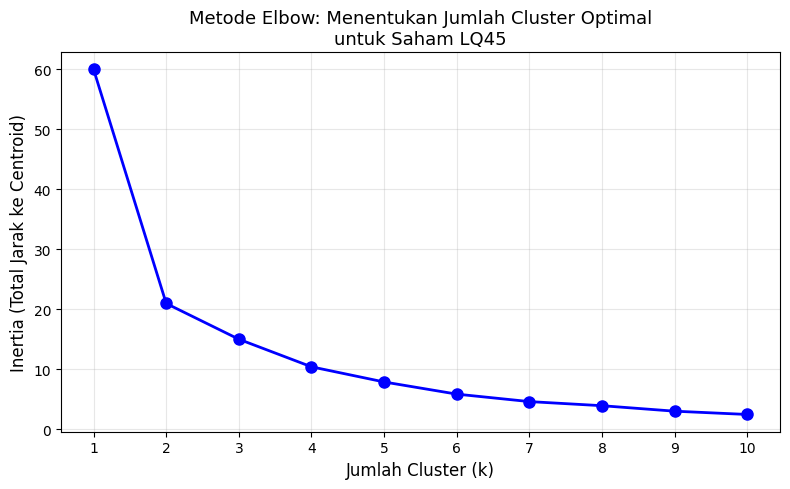

Grafik Elbow Method disimpan sebagai 'elbow_method.png'
→ Lihat grafik: pilih k di 'siku' kurva (biasanya k=3 atau k=4)


In [ ]:
# Sebelum menjalankan K-Means, kita perlu menentukan berapa kelompok (k)
# yang paling tepat untuk data kita.
# "Elbow Method" membantu kita memilih k yang optimal:
# - Coba berbagai nilai k (1 sampai 10)
# - Hitung "inertia" = total jarak setiap titik ke pusat clusternya
# - Pilih k di mana penurunan inertia mulai melambat (titik "siku"/elbow)
print("\n--- Menentukan jumlah cluster optimal dengan Metode Elbow ---")

inertia_list = []       # List untuk menyimpan nilai inertia di setiap k
k_range = range(1, 11)  # Kita coba k dari 1 sampai 10

for k in k_range:
    # Buat dan latih model K-Means untuk setiap nilai k
    kmeans_temp = KMeans(
        n_clusters=k,       # Jumlah cluster yang dicoba
        random_state=42,    # Seed angka acak agar hasil reproducible (bisa diulang)
        n_init=10           # Coba 10 inisialisasi berbeda, ambil yang terbaik
    )
    kmeans_temp.fit(X_normalized)  # Latih model dengan data yang sudah dinormalisasi
    inertia_list.append(kmeans_temp.inertia_)  # Simpan nilai inertia
    # inertia_ = total kuadrat jarak semua titik ke pusat clusternya (semakin kecil = semakin baik)

# Buat grafik Elbow
plt.figure(figsize=(8, 5))  # Ukuran grafik: lebar 8 inch, tinggi 5 inch
plt.plot(
    k_range,           # Sumbu X: jumlah cluster (1-10)
    inertia_list,      # Sumbu Y: nilai inertia
    'bo-',             # 'b'=biru, 'o'=lingkaran di titik data, '-'=garis penghubung
    linewidth=2,       # Tebal garis
    markersize=8       # Ukuran titik data
)
plt.xlabel('Jumlah Cluster (k)', fontsize=12)   # Label sumbu X
plt.ylabel('Inertia (Total Jarak ke Centroid)', fontsize=12)  # Label sumbu Y
plt.title('Metode Elbow: Menentukan Jumlah Cluster Optimal\nuntuk Saham LQ45', fontsize=13)
plt.xticks(k_range)       # Tampilkan semua angka k di sumbu X
plt.grid(True, alpha=0.3) # Tambahkan grid tipis agar lebih mudah dibaca
plt.tight_layout()        # Atur layout agar tidak ada yang terpotong
plt.savefig('elbow_method.png', dpi=150, bbox_inches='tight')  # Simpan gambar
plt.show()
print("Grafik Elbow Method disimpan sebagai 'elbow_method.png'")
print("→ Lihat grafik: pilih k di 'siku' kurva (biasanya k=3 atau k=4)")

---
## Bagian 7: Menjalankan Algoritma K-Means Clustering
**K-Means** bekerja dengan cara:
1. Menempatkan K centroid secara acak
2. Menugaskan setiap saham ke centroid terdekat
3. Memperbarui posisi centroid berdasarkan rata-rata anggotanya
4. Mengulang langkah 2–3 hingga centroid tidak berubah lagi


In [ ]:
# Berdasarkan grafik elbow, kita pilih k=3 (3 kelompok)
# 3 kelompok intuitif untuk saham:
# - Kelompok "Kalem": volatilitas rendah, return stabil
# - Kelompok "Moderat": volatilitas dan return sedang
# - Kelompok "Lincah": volatilitas tinggi, pergerakan drastis
JUMLAH_CLUSTER = 3  # Kita bisa ubah angka ini setelah melihat grafik elbow

print(f"\n--- Menjalankan K-Means Clustering dengan k={JUMLAH_CLUSTER} ---")

# Buat model K-Means
kmeans = KMeans(
    n_clusters=JUMLAH_CLUSTER,  # Jumlah kelompok yang ingin dibuat
    random_state=42,            # Seed untuk reproducibility
    n_init=10,                  # Jumlah percobaan inisialisasi
    max_iter=300                # Jumlah iterasi maksimum sampai konvergen
)

# Latih model dan prediksi cluster untuk setiap saham
label_cluster = kmeans.fit_predict(X_normalized)
# fit_predict() = dua langkah:
# 1. fit() = cari centroid optimal (pusat setiap cluster)
# 2. predict() = tentukan setiap saham masuk ke cluster mana (0, 1, atau 2)

# Tambahkan hasil cluster ke DataFrame fitur
df_fitur['Cluster'] = label_cluster  # Tambah kolom cluster (0, 1, atau 2)

print(f"K-Means selesai! Distribusi saham per cluster:")
print(df_fitur['Cluster'].value_counts().sort_index())


--- Menjalankan K-Means Clustering dengan k=3 ---
K-Means selesai! Distribusi saham per cluster:
Cluster
0    16
1     3
2    11
Name: count, dtype: int64


---
## Bagian 8: Interpretasi & Penamaan Cluster
Setelah K-Means membagi saham ke dalam cluster, saya menganalisis karakteristik rata-rata tiap cluster untuk memberikan **nama/label yang bermakna**, misalnya: Saham Defensif, Saham Agresif, dan Saham Moderat


In [ ]:
# Setelah K-Means membagi saham ke dalam cluster, kita perlu memahami
# makna setiap cluster dengan melihat statistik rata-ratanya
print("\n--- Analisis Karakteristik Setiap Cluster ---")

# Hitung rata-rata fitur untuk setiap cluster
ringkasan_cluster = df_fitur.groupby('Cluster').agg({
    'Volatilitas (%)': 'mean',               # Rata-rata volatilitas per cluster
    'Return Harian Rata-rata (%)': 'mean',   # Rata-rata return per cluster
    'Harga Terakhir (Rp)': 'mean'            # Rata-rata harga per cluster
}).round(4)
# groupby('Cluster') = kelompokkan berdasarkan nomor cluster
# agg() = hitung statistik untuk setiap kelompok

print("\nRata-rata karakteristik setiap cluster:")
print(ringkasan_cluster)

# Beri nama yang bermakna untuk setiap cluster
# (nama ini bisa kamu sesuaikan berdasarkan ringkasan_cluster di atas)
nama_cluster = {
    0: '🐢 Saham Defensif (Kalem)',    # Volatilitas rendah, cocok investasi aman
    1: '⚡ Saham Agresif (Lincah)',    # Volatilitas tinggi, cocok trader aktif
    2: '⚖️  Saham Moderat (Seimbang)'  # Di tengah-tengah
}

# Tambahkan nama cluster ke DataFrame
df_fitur['Nama Cluster'] = df_fitur['Cluster'].map(nama_cluster)

print("\nDaftar saham beserta klusternya:")
print(df_fitur[['Volatilitas (%)', 'Return Harian Rata-rata (%)', 'Nama Cluster']].to_string())


--- Analisis Karakteristik Setiap Cluster ---

Rata-rata karakteristik setiap cluster:
         Volatilitas (%)  Return Harian Rata-rata (%)  Harga Terakhir (Rp)
Cluster                                                                   
0                 2.0605                      -0.0847            2613.3125
1                 4.1441                       0.2363            7863.3333
2                 3.1723                       0.0976            3185.4545

Daftar saham beserta klusternya:
      Volatilitas (%)  Return Harian Rata-rata (%)                  Nama Cluster
ACES         1.778505                    -0.105138      🐢 Saham Defensif (Kalem)
ADRO         2.488534                     0.143715  ⚖️  Saham Moderat (Seimbang)
ANTM         3.640930                     0.066645  ⚖️  Saham Moderat (Seimbang)
ASII         2.599977                     0.085151  ⚖️  Saham Moderat (Seimbang)
BBCA         2.023644                    -0.104808      🐢 Saham Defensif (Kalem)
BBRI         1.97

---
## 📉 Bagian 9: Visualisasi Hasil Clustering (Scatter Plot)
Saya menggunakan **PCA (Principal Component Analysis)** untuk mereduksi dimensi fitur menjadi 2D sehingga hasil clustering dapat divisualisasikan dalam bentuk scatter plot yang mudah dipahami.



--- Membuat Visualisasi Hasil Clustering ---


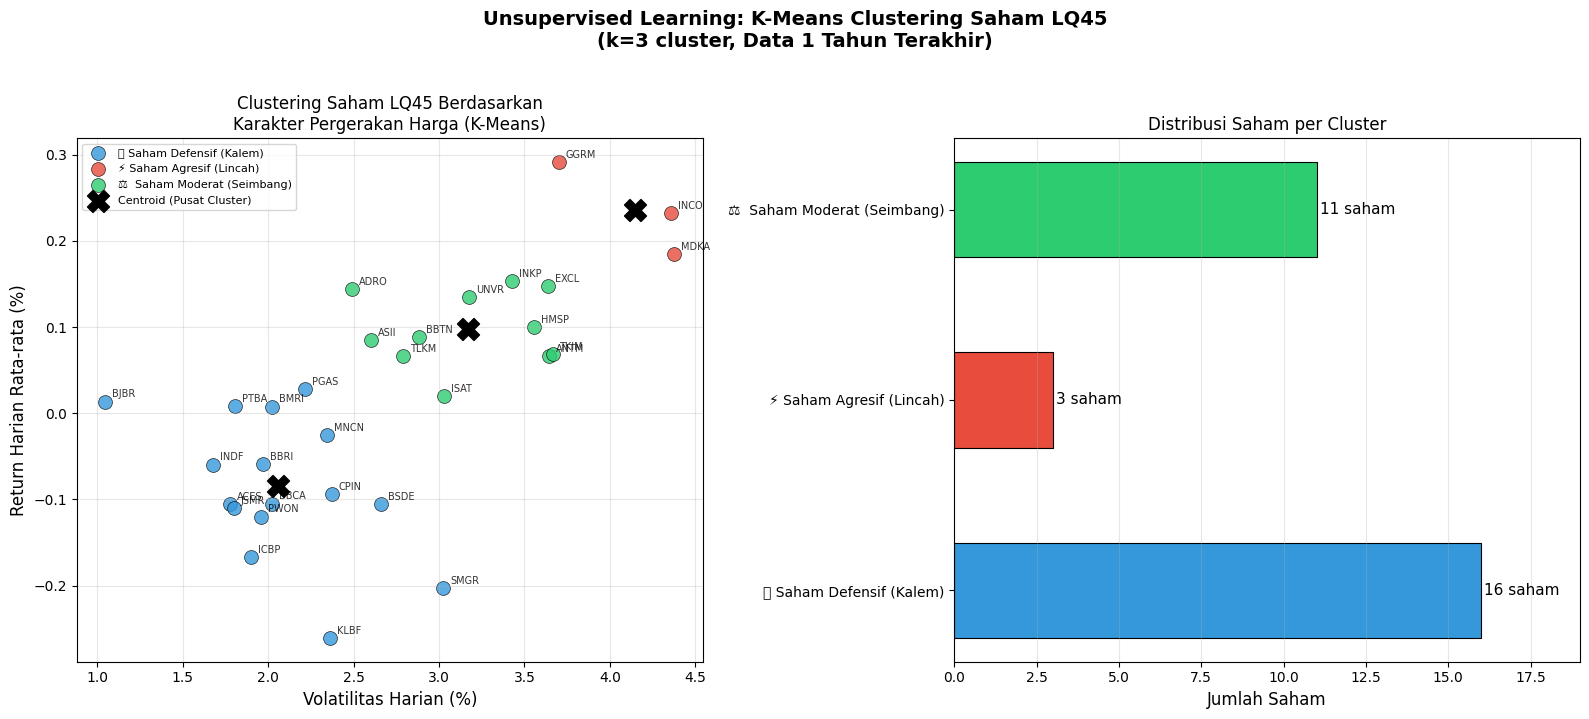

Grafik clustering disimpan sebagai 'clustering_saham_lq45.png'


In [ ]:
# Visualisasi ini menampilkan setiap saham sebagai titik di grafik 2D
# - Sumbu X: Volatilitas
# - Sumbu Y: Return Rata-rata Harian
# - Warna titik: menunjukkan cluster/kelompok
# Saham yang dekat satu sama lain = karakter pergerakannya mirip
print("\n--- Membuat Visualisasi Hasil Clustering ---")

# Definisikan warna untuk setiap cluster
warna_cluster = {0: '#3498db', 1: '#e74c3c', 2: '#2ecc71'}
# Biru = cluster 0, Merah = cluster 1, Hijau = cluster 2

# Ambil data centroid (titik pusat setiap cluster) dalam skala asli
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
# inverse_transform() = kembalikan data dari skala normalisasi ke skala asli
# cluster_centers_ = koordinat pusat setiap cluster dalam skala normalisasi

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
# Buat canvas dengan 2 subplot berdampingan (1 baris, 2 kolom)
# figsize=(16,7) = lebar 16 inch, tinggi 7 inch

# ======= SUBPLOT 1: Scatter Plot Volatilitas vs Return =======
ax1 = axes[0]

for cluster_id in range(JUMLAH_CLUSTER):
    # Filter data untuk setiap cluster
    mask = df_fitur['Cluster'] == cluster_id  # Boolean mask: True jika cluster sesuai
    data_cluster = df_fitur[mask]             # Ambil hanya baris yang sesuai cluster

    # Plot titik-titik saham dalam cluster ini
    ax1.scatter(
        data_cluster['Volatilitas (%)'],            # Sumbu X: volatilitas
        data_cluster['Return Harian Rata-rata (%)'], # Sumbu Y: return
        c=warna_cluster[cluster_id],                # Warna berdasarkan cluster
        label=nama_cluster[cluster_id],             # Label untuk legenda
        alpha=0.8,                                  # Transparansi 80% agar titik yang overlap terlihat
        s=100,                                      # Ukuran titik (s=size)
        edgecolors='black',                         # Tepian titik berwarna hitam
        linewidth=0.5                               # Ketebalan tepian
    )

    # Tambahkan label nama saham di setiap titik
    for ticker, row in data_cluster.iterrows():
        ax1.annotate(
            ticker,                                          # Teks label (nama saham)
            (row['Volatilitas (%)'], row['Return Harian Rata-rata (%)']),  # Posisi titik
            textcoords="offset points",                      # Sistem koordinat offset
            xytext=(5, 3),                                   # Geser label: 5px kanan, 3px atas
            fontsize=7,                                      # Ukuran font label
            alpha=0.8                                        # Transparansi label
        )

# Plot titik centroid (pusat cluster) dengan tanda X besar
ax1.scatter(
    centroids[:, 0],    # Koordinat X semua centroid (kolom 0 = Volatilitas)
    centroids[:, 1],    # Koordinat Y semua centroid (kolom 1 = Return)
    c='black',          # Warna centroid: hitam agar menonjol
    marker='X',         # Bentuk marker: X
    s=250,              # Ukuran besar agar mudah dilihat
    zorder=5,           # Tampilkan di atas layer lain
    label='Centroid (Pusat Cluster)'  # Label untuk legenda
)

ax1.set_xlabel('Volatilitas Harian (%)', fontsize=12)
ax1.set_ylabel('Return Harian Rata-rata (%)', fontsize=12)
ax1.set_title('Clustering Saham LQ45 Berdasarkan\nKarakter Pergerakan Harga (K-Means)', fontsize=12)
ax1.legend(loc='upper left', fontsize=8)  # Tampilkan legenda di kiri atas
ax1.grid(True, alpha=0.3)                 # Grid tipis

# ======= SUBPLOT 2: Bar Chart Distribusi Saham per Cluster =======
ax2 = axes[1]

# Hitung jumlah saham di setiap cluster
distribusi = df_fitur['Cluster'].value_counts().sort_index()  # Hitung per cluster
nama_untuk_plot = [nama_cluster[i] for i in distribusi.index]  # Nama cluster
warna_untuk_plot = [warna_cluster[i] for i in distribusi.index]  # Warna cluster

# Buat bar chart horizontal
bars = ax2.barh(
    nama_untuk_plot,       # Label di sumbu Y (nama cluster)
    distribusi.values,     # Nilai di sumbu X (jumlah saham)
    color=warna_untuk_plot, # Warna batang
    edgecolor='black',     # Tepian batang
    linewidth=0.8,         # Ketebalan tepian
    height=0.5             # Tinggi batang
)

# Tambahkan angka di ujung setiap batang
for bar, val in zip(bars, distribusi.values):
    ax2.text(
        bar.get_width() + 0.1,  # Posisi X: sedikit di luar ujung batang
        bar.get_y() + bar.get_height() / 2,  # Posisi Y: tengah batang
        f'{val} saham',         # Teks yang ditampilkan
        va='center',            # Vertikal alignment: tengah
        fontsize=11             # Ukuran font
    )

ax2.set_xlabel('Jumlah Saham', fontsize=12)
ax2.set_title('Distribusi Saham per Cluster', fontsize=12)
ax2.set_xlim(0, distribusi.max() + 3)  # Beri ruang di kanan untuk label
ax2.grid(True, alpha=0.3, axis='x')    # Grid hanya di sumbu X

plt.suptitle(
    'Unsupervised Learning: K-Means Clustering Saham LQ45\n'
    f'(k={JUMLAH_CLUSTER} cluster, Data 1 Tahun Terakhir)',
    fontsize=14, fontweight='bold', y=1.02  # Judul utama di atas kedua subplot
)
plt.tight_layout()
plt.savefig('clustering_saham_lq45.png', dpi=150, bbox_inches='tight')
plt.show()
print("Grafik clustering disimpan sebagai 'clustering_saham_lq45.png'")

---
## Bagian 10: Ringkasan Hasil & Kesimpulan
Merangkum temuan dari proses clustering: profil tiap cluster, anggota saham di masing-masing kelompok, dan insight yang dapat diambil untuk keperluan analisis portofolio.



In [ ]:
print("\n" + "="*60)
print("RINGKASAN HASIL CLUSTERING SAHAM LQ45")
print("="*60)

for cluster_id in range(JUMLAH_CLUSTER):
    # Filter saham dalam cluster ini
    saham_dalam_cluster = df_fitur[df_fitur['Cluster'] == cluster_id]
    stats = saham_dalam_cluster[['Volatilitas (%)', 'Return Harian Rata-rata (%)']].mean()

    print(f"\n{nama_cluster[cluster_id]}")
    print(f"  Jumlah saham : {len(saham_dalam_cluster)} saham")
    print(f"  Volatilitas rata-rata  : {stats['Volatilitas (%)']:.4f}%")
    print(f"  Return harian rata-rata: {stats['Return Harian Rata-rata (%)']:.4f}%")
    print(f"  Daftar saham : {', '.join(saham_dalam_cluster.index.tolist())}")

print("\n" + "="*60)
print("INTERPRETASI HASIL:")
print("="*60)
print("""
Cluster dengan VOLATILITAS RENDAH → Saham Defensif/Kalem
  → Cocok untuk: Investor jangka panjang yang mencari keamanan
  → Contoh tipikal: Bank besar (BBCA, BBRI, BMRI), Telkom (TLKM)

Cluster dengan VOLATILITAS TINGGI → Saham Agresif/Lincah
  → Cocok untuk: Trader aktif yang mau ambil risiko besar
  → Contoh tipikal: Saham pertambangan (ANTM, MDKA), saham kecil

Cluster MODERAT → Di antara keduanya
  → Cocok untuk: Investor yang mau pertumbuhan tapi tetap terkontrol

CATATAN PENTING:
- Ini adalah analisis HISTORIS berdasarkan data 1 tahun terakhir
- Karakter saham bisa berubah seiring waktu dan kondisi pasar
- Hasil clustering BUKAN rekomendasi investasi!
- Selalu lakukan riset mendalam sebelum berinvestasi
""")
print("="*60)
print("✅ Program Unsupervised Learning selesai dijalankan!")
print("="*60)


RINGKASAN HASIL CLUSTERING SAHAM LQ45

🐢 Saham Defensif (Kalem)
  Jumlah saham : 16 saham
  Volatilitas rata-rata  : 2.0605%
  Return harian rata-rata: -0.0847%
  Daftar saham : ACES, BBCA, BBRI, BJBR, BMRI, BSDE, CPIN, ICBP, INDF, JSMR, KLBF, MNCN, PGAS, PTBA, PWON, SMGR

⚡ Saham Agresif (Lincah)
  Jumlah saham : 3 saham
  Volatilitas rata-rata  : 4.1441%
  Return harian rata-rata: 0.2363%
  Daftar saham : GGRM, INCO, MDKA

⚖️  Saham Moderat (Seimbang)
  Jumlah saham : 11 saham
  Volatilitas rata-rata  : 3.1723%
  Return harian rata-rata: 0.0976%
  Daftar saham : ADRO, ANTM, ASII, BBTN, EXCL, HMSP, INKP, ISAT, TKIM, TLKM, UNVR

INTERPRETASI HASIL:

Cluster dengan VOLATILITAS RENDAH → Saham Defensif/Kalem
  → Cocok untuk: Investor jangka panjang yang mencari keamanan
  → Contoh tipikal: Bank besar (BBCA, BBRI, BMRI), Telkom (TLKM)

Cluster dengan VOLATILITAS TINGGI → Saham Agresif/Lincah
  → Cocok untuk: Trader aktif yang mau ambil risiko besar
  → Contoh tipikal: Saham pertambangan (